# Nifty 50 Futures — Daily 2-Position Momentum Strategy (₹3L)

Concentrated long-short strategy: **2 futures contracts**, refreshed **every trading day**.

| | |
|---|---|
| **Long** | #1 composite momentum stock → BUY futures |
| **Short** | #50 composite momentum stock → SELL futures |
| **Capital** | ₹3,00,000  (₹1.5L per leg, equal weight) |
| **Rebalance** | Daily — positions re-evaluated every trading day |
| **Cost** | 0.05% per leg, charged only when the ticker changes |

**Signal inputs (computed on daily closes):**

| Signal | Window | Weight |
|--------|--------|--------|
| ROC_6mo | 130 trading days | 30% |
| ROC_3mo | 65 trading days | 20% |
| ROC_1mo | 20 trading days | 10% |
| MA_Cross | EMA(8) vs EMA(21) | 15% |
| MACD_Hist | 12/26/9 | 15% |
| High52w | 252-day high ratio | 10% |

**Output:** Final cell prints today's LONG / SHORT calls with ₹ allocated.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import yfinance as yf
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from datetime import date, timedelta

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.float_format", "{:.4f}".format)

print("Packages loaded successfully.")


Packages loaded successfully.


In [2]:
# ── Nifty 50 universe — static ~Jan-2022 snapshot (survivorship-bias reduced) ──
NIFTY50_TICKERS = [
    "ADANIENT.NS",   "ADANIPORTS.NS", "APOLLOHOSP.NS", "ASIANPAINT.NS", "AXISBANK.NS",
    "BAJAJ-AUTO.NS", "BAJAJFINSV.NS", "BAJFINANCE.NS", "BHARTIARTL.NS", "BPCL.NS",
    "BRITANNIA.NS",  "CIPLA.NS",      "COALINDIA.NS",  "DIVISLAB.NS",   "DRREDDY.NS",
    "EICHERMOT.NS",  "GRASIM.NS",     "HCLTECH.NS",    "HDFCBANK.NS",   "HDFC.NS",
    "HDFCLIFE.NS",   "HEROMOTOCO.NS", "HINDALCO.NS",   "HINDUNILVR.NS", "ICICIBANK.NS",
    "INDUSINDBK.NS", "INFY.NS",       "ITC.NS",        "JSWSTEEL.NS",   "KOTAKBANK.NS",
    "LT.NS",         "M&M.NS",        "MARUTI.NS",     "NESTLEIND.NS",  "NTPC.NS",
    "ONGC.NS",       "POWERGRID.NS",  "RELIANCE.NS",   "SBIN.NS",       "SBILIFE.NS",
    "SHREECEM.NS",   "SUNPHARMA.NS",  "TATACONSUM.NS", "TATAMOTORS.NS", "TATASTEEL.NS",
    "TCS.NS",        "TECHM.NS",      "TITAN.NS",      "ULTRACEMCO.NS", "WIPRO.NS",
]

BENCHMARK        = "^NSEI"
RISK_FREE_ANNUAL = 0.065
RISK_FREE_DAILY  = RISK_FREE_ANNUAL / 252   # daily risk-free rate

# ── Capital ────────────────────────────────────────────────────────────────────
INITIAL_CAPITAL = 300_000   # ₹3,00,000

# ── Strategy parameters ───────────────────────────────────────────────────────
TOP_N          = 1       # 1 long + 1 short = 2 futures positions
BACKTEST_YEARS = 3
ROLLING_DAYS   = 252     # 1-year warm-up  (enough for 52-week-high signal)

# Indicator windows in TRADING DAYS
ROC_SHORT       = 20    # ~1 month
ROC_MED         = 65    # ~3 months
ROC_LONG        = 130   # ~6 months (standard cross-sectional momentum)
RSI_WINDOW      = 14
EMA_FAST, EMA_SLOW               = 8, 21
MACD_FAST, MACD_SLOW, MACD_SIG  = 12, 26, 9
HIGH52W_WINDOW  = 252   # 1-year high

# Composite signal weights — must sum to 1.0
SIGNAL_WEIGHTS = {
    "ROC_6mo":   0.30,
    "ROC_3mo":   0.20,
    "ROC_1mo":   0.10,
    "MA_Cross":  0.15,
    "MACD_Hist": 0.15,
    "High52w":   0.10,
}

# ── Risk management ───────────────────────────────────────────────────────────
VIX_LOW           = 15.0    # full exposure below this
VIX_HIGH          = 20.0    # flat at or above this
STOP_LOSS_PCT      = 0.05   # 5% per-position stop-loss from entry
PORTFOLIO_DD_LIMIT = 0.10   # 10% portfolio drawdown → go flat
COOL_OFF_DAYS      = 5      # trading days to sit in cash after DD trigger
COST_ONE_WAY       = 0.0005 # 0.05% per leg (futures: brokerage + STT on sell)

# Equal allocation: half the portfolio per leg
LONG_WEIGHT  = 0.50
SHORT_WEIGHT = 0.50

END_DATE   = date.today()
# Download extra year for warm-up: total = BACKTEST_YEARS + 1yr warm-up
START_DATE = END_DATE - timedelta(days=int((BACKTEST_YEARS + 1) * 365) + 30)

print(f"Universe        : {len(NIFTY50_TICKERS)} Nifty 50 tickers (static ~Jan-2022 snapshot)")
print(f"Starting capital: ₹{INITIAL_CAPITAL:,.0f}")
print(f"Allocation      : ₹{int(INITIAL_CAPITAL * LONG_WEIGHT):,} per leg  (equal weight, 2 positions)")
print(f"Download period : {START_DATE}  →  {END_DATE}")
print(f"Rebalance       : Daily")
print(f"Long            : #1 composite momentum stock → BUY futures")
print(f"Short           : #50 composite momentum stock → SELL futures")
print(f"Signal mix      : {', '.join(f'{k}={v:.0%}' for k, v in SIGNAL_WEIGHTS.items())}")
print(f"Stop-loss       : {STOP_LOSS_PCT:.0%}  |  DD limit: {PORTFOLIO_DD_LIMIT:.0%}")


Universe        : 50 Nifty 50 tickers (static ~Jan-2022 snapshot)
Starting capital: ₹300,000
Allocation      : ₹150,000 per leg  (equal weight, 2 positions)
Download period : 2022-04-16  →  2026-05-15
Rebalance       : Daily
Long            : #1 composite momentum stock → BUY futures
Short           : #50 composite momentum stock → SELL futures
Signal mix      : ROC_6mo=30%, ROC_3mo=20%, ROC_1mo=10%, MA_Cross=15%, MACD_Hist=15%, High52w=10%
Stop-loss       : 5%  |  DD limit: 10%


In [5]:
# ── Download daily historical prices ─────────────────────────────────────────
all_tickers = NIFTY50_TICKERS + [BENCHMARK]

print(f"Downloading {len(all_tickers)} instruments ({START_DATE} → {END_DATE}) …")
raw_daily = yf.download(
    all_tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False,
)["Close"]

# Drop instruments with >10% missing data; forward-fill remaining gaps
raw_daily = raw_daily.dropna(axis=1, thresh=int(len(raw_daily) * 0.90))
raw_daily = raw_daily.ffill()

valid_stocks   = [t for t in NIFTY50_TICKERS if t in raw_daily.columns]
stock_prices   = raw_daily[valid_stocks]                    # daily close prices
stock_returns  = stock_prices.pct_change().dropna()         # daily returns
market_returns = raw_daily[BENCHMARK].pct_change().reindex(stock_returns.index).fillna(0)

backtest_start = stock_returns.index[ROLLING_DAYS].date()

print(f"Trading days downloaded  : {len(raw_daily)}")
print(f"Stocks with valid data   : {len(valid_stocks)}")
print(f"Warm-up                  : {ROLLING_DAYS} days")
print(f"Backtest window starts   : {backtest_start}")
stock_returns.tail(3)


$TATAMOTORS.NS: possibly delisted; no timezone found
$HDFC.NS: possibly delisted; no timezone found

2 Failed downloads:
['TATAMOTORS.NS', 'HDFC.NS']: possibly delisted; no timezone found


Trading days downloaded  : 1008
Stocks with valid data   : 48
Warm-up                  : 252 days
Backtest window starts   : 2023-04-25


Ticker,ADANIENT.NS,ADANIPORTS.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AXISBANK.NS,BAJAJ-AUTO.NS,BAJAJFINSV.NS,BAJFINANCE.NS,BHARTIARTL.NS,BPCL.NS,...,SBILIFE.NS,SHREECEM.NS,SUNPHARMA.NS,TATACONSUM.NS,TATASTEEL.NS,TCS.NS,TECHM.NS,TITAN.NS,ULTRACEMCO.NS,WIPRO.NS
Date,,,,,,,,,,,,,,,,,,,,,
2026-05-12,-0.0380,-0.0448,-0.0074,-0.0236,-0.0096,-0.0187,-0.0275,-0.0340,-0.0017,-0.0224,...,-0.0268,-0.0137,-0.0144,-0.0142,-0.0004,-0.0387,-0.0443,-0.0357,-0.0295,-0.0362
2026-05-13,0.0386,0.0294,-0.0022,0.0447,-0.0035,-0.0130,-0.0091,-0.0089,0.0184,0.0321,...,0.0020,0.0054,-0.0113,-0.0144,0.0359,-0.0120,-0.0129,0.0087,0.0049,-0.0093
2026-05-14,0.0860,0.0205,0.0143,0.0018,-0.0009,0.0184,0.0065,0.0179,0.0527,-0.0071,...,0.0159,0.0012,0.0210,-0.0054,0.0069,-0.0118,-0.0230,0.0109,0.0103,0.0027


In [6]:
# ── Momentum indicator functions — all operate on pd.Series of weekly closes ──

def compute_roc(prices, window):
    """Rate of Change: (price_t / price_{t-window}) - 1"""
    return prices.pct_change(window)


def compute_rsi(prices, window=14):
    """RSI using Wilder's EWM smoothing.  Returns 0–100 series."""
    delta    = prices.diff()
    gain     = delta.clip(lower=0)
    loss     = -delta.clip(upper=0)
    avg_gain = gain.ewm(com=window - 1, min_periods=window, adjust=False).mean()
    avg_loss = loss.ewm(com=window - 1, min_periods=window, adjust=False).mean()
    rs       = avg_gain / avg_loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))


def compute_macd_hist(prices, fast=12, slow=26, signal=9):
    """MACD histogram = MACD line − signal line."""
    ema_fast    = prices.ewm(span=fast,   adjust=False).mean()
    ema_slow    = prices.ewm(span=slow,   adjust=False).mean()
    macd_line   = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    return macd_line - signal_line


def compute_ma_cross(prices, fast=8, slow=21):
    """Normalised EMA crossover: (EMA_fast − EMA_slow) / price."""
    ema_fast = prices.ewm(span=fast, adjust=False).mean()
    ema_slow = prices.ewm(span=slow, adjust=False).mean()
    denom    = prices.replace(0, np.nan)
    return (ema_fast - ema_slow) / denom


def compute_high52w_ratio(prices, window=52):
    """price / rolling 52-week high — proximity to breakout level."""
    high52 = prices.rolling(window, min_periods=26).max()
    return prices / high52.replace(0, np.nan)


print("Momentum indicator functions defined.")
print("  compute_roc, compute_rsi, compute_macd_hist, compute_ma_cross, compute_high52w_ratio")


Momentum indicator functions defined.
  compute_roc, compute_rsi, compute_macd_hist, compute_ma_cross, compute_high52w_ratio


In [7]:
# ── Build per-signal DataFrames (rows = trading days, columns = stocks) ──────
# price_panel is daily closes; windows are in trading days
price_panel = stock_prices

raw_signals = {s: {} for s in SIGNAL_WEIGHTS}

for ticker in valid_stocks:
    p = price_panel[ticker]
    raw_signals["ROC_6mo"][ticker]   = compute_roc(p, ROC_LONG)          # 130d
    raw_signals["ROC_3mo"][ticker]   = compute_roc(p, ROC_MED)           # 65d
    raw_signals["ROC_1mo"][ticker]   = compute_roc(p, ROC_SHORT)         # 20d
    raw_signals["MACD_Hist"][ticker] = compute_macd_hist(p, MACD_FAST, MACD_SLOW, MACD_SIG)
    raw_signals["MA_Cross"][ticker]  = compute_ma_cross(p, EMA_FAST, EMA_SLOW)
    raw_signals["High52w"][ticker]   = compute_high52w_ratio(p, HIGH52W_WINDOW)  # 252d

signal_dfs = {k: pd.DataFrame(v, index=price_panel.index) for k, v in raw_signals.items()}

print("Signal panels built (daily):")
for name, df in signal_dfs.items():
    nan_pct = df.isna().mean().mean()
    print(f"  {name:12s}: {df.shape[0]} days × {df.shape[1]} stocks  (NaN = {nan_pct:.1%})")


Signal panels built (daily):
  ROC_6mo     : 1008 days × 48 stocks  (NaN = 12.9%)
  ROC_3mo     : 1008 days × 48 stocks  (NaN = 6.4%)
  ROC_1mo     : 1008 days × 48 stocks  (NaN = 2.0%)
  MA_Cross    : 1008 days × 48 stocks  (NaN = 0.0%)
  MACD_Hist   : 1008 days × 48 stocks  (NaN = 0.0%)
  High52w     : 1008 days × 48 stocks  (NaN = 2.5%)


In [8]:
# ── Cross-sectional z-scoring and composite score ─────────────────────────────
#
# At each day i we:
#   1. Take the cross-sectional slice (one value per stock) for each signal
#   2. Z-score it: (x - mean) / std  — relative rank across universe matters
#   3. Weight and sum the z-scores → composite momentum score
#   4. Rank stocks: #1 = LONG, #50 = SHORT

def composite_score_at(i):
    """
    Return pd.Series of composite momentum scores at bar index i.
    Higher score = stronger positive momentum (LONG candidate).
    Returns None if insufficient history.
    """
    if i < ROLLING_DAYS:
        return None

    weighted_z = {}
    for name, weight in SIGNAL_WEIGHTS.items():
        row   = signal_dfs[name].iloc[i]
        valid = row.dropna()
        if len(valid) < 10:
            continue
        mu, sigma = valid.mean(), valid.std()
        if sigma < 1e-9:
            continue
        z = (valid - mu) / sigma
        weighted_z[name] = z * weight

    if not weighted_z:
        return None

    combined = pd.concat(weighted_z.values(), axis=1).sum(axis=1, skipna=False)
    return combined.dropna()


# ── Quick preview: latest-day composite scores ────────────────────────────────
latest_i      = len(price_panel) - 1
latest_scores = composite_score_at(latest_i)

if latest_scores is not None:
    sorted_scores = latest_scores.sort_values(ascending=False)
    print(f"=== Composite Momentum Scores — {price_panel.index[latest_i].date()} ===")
    print(f"{'Rank':<5} {'Ticker':<16} {'Score':>8}   Signal")
    print("-" * 50)
    n = len(sorted_scores)
    for rank, (ticker, score) in enumerate(sorted_scores.items(), 1):
        if rank <= TOP_N:
            sig = "LONG  ▲  ← BUY futures"
        elif rank > n - TOP_N:
            sig = "SHORT ▼  ← SELL futures"
        else:
            sig = "neutral"
            if rank > TOP_N + 4 and rank < n - TOP_N - 4:
                continue  # skip middle for readability
        print(f"{rank:<5} {ticker:<16} {score:>8.4f}   {sig}")
else:
    print("Not enough history yet.")


=== Composite Momentum Scores — 2026-05-14 ===
Rank  Ticker              Score   Signal
--------------------------------------------------
1     ADANIENT.NS        1.4388   LONG  ▲  ← BUY futures
2     ADANIPORTS.NS      1.3360   neutral
3     HINDALCO.NS        1.3288   neutral
4     BAJAJ-AUTO.NS      1.2542   neutral
5     NESTLEIND.NS       1.0790   neutral
43    BPCL.NS           -0.8728   neutral
44    HDFCBANK.NS       -0.9530   neutral
45    WIPRO.NS          -1.0907   neutral
46    TCS.NS            -1.6295   neutral
47    INFY.NS           -1.6649   neutral
48    HCLTECH.NS        -1.7766   SHORT ▼  ← SELL futures


In [9]:
# ── Daily India VIX regime filter ────────────────────────────────────────────
print("Downloading India VIX (daily) …")
_vix_dl   = yf.download("^INDIAVIX", start=START_DATE, end=END_DATE,
                         auto_adjust=True, progress=False)["Close"]
vix_raw   = _vix_dl.squeeze() if isinstance(_vix_dl, pd.DataFrame) else _vix_dl

# Align to trading calendar of stock_returns; forward-fill gaps
vix_daily = vix_raw.reindex(stock_returns.index, method="ffill")

full_d = int((vix_daily < VIX_LOW).sum())
half_d = int(((vix_daily >= VIX_LOW) & (vix_daily < VIX_HIGH)).sum())
flat_d = int((vix_daily >= VIX_HIGH).sum())
print(f"VIX range       : {float(vix_daily.min()):.1f} – {float(vix_daily.max()):.1f}")
print(f"Full exposure   : {full_d} days  (VIX < {VIX_LOW})")
print(f"Half exposure   : {half_d} days  ({VIX_LOW} ≤ VIX < {VIX_HIGH})")
print(f"Flat / cash     : {flat_d} days  (VIX ≥ {VIX_HIGH})")


def vix_scale(day):
    """Return exposure multiplier (0, 0.5, or 1.0) based on India VIX on given day."""
    if day not in vix_daily.index:
        return 1.0
    v = float(vix_daily.loc[day])
    if np.isnan(v):
        return 1.0
    if v >= VIX_HIGH:
        return 0.0
    if v >= VIX_LOW:
        return 0.5
    return 1.0


VIX range       : 9.1 – 27.9
Full exposure   : 651 days  (VIX < 15.0)
Half exposure   : 262 days  (15.0 ≤ VIX < 20.0)
Flat / cash     : 94 days  (VIX ≥ 20.0)


  HIGH-CONVICTION DAY (HCD) PREDICTOR — Walk-forward LogReg
  Conviction threshold : top 30% of days by score spread
  Precision  : 55.82%  (of predicted HCDs, how many actually are?)
  Recall     : 76.37%  (of actual HCDs, how many does it catch?)
  ROC-AUC    : 0.849  (0.5 = coin flip, 1.0 = perfect)
  Trade freq : 41.6% of days  (naive base rate = 30%)
  HCDs in history : 232 / 756 days


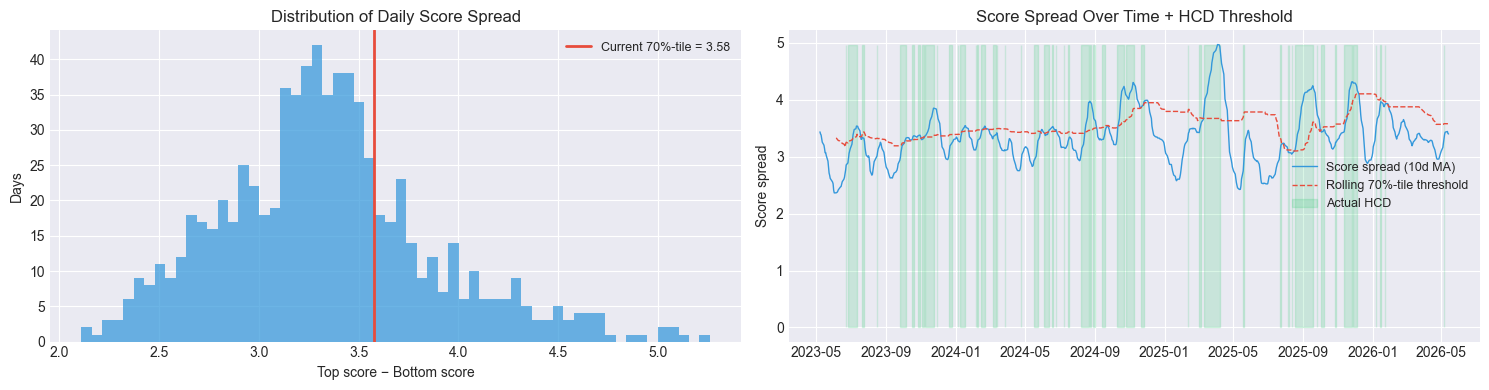

In [10]:
# ── High-Conviction Day (HCD) Detector & Walk-Forward Predictor ───────────────
#
# "Big momentum day" = a trading day where the cross-sectional SCORE SPREAD is
# in the top 30% historically: the composite signals strongly differentiate
# momentum winners from losers.
#
#   score_spread(t) = composite_score_rank1(t) − composite_score_rankN(t)
#
# Walk-forward logistic regression (no look-ahead bias):
#   Train on all data up to day t → predict whether day t+1 is an HCD.
#   Features: spread lags, spread EMA, VIX level, VIX change, 5d market return,
#             rolling percentile rank of yesterday's spread.
#
# Backtest rule:
#   • Predicted HCD  → REFRESH positions (re-run signal, pay cost only if ticker changed)
#   • Non-HCD day    → HOLD current positions (zero cost, full carry)
#   • Stop-loss      → monitored every day regardless of HCD status

try:
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import Pipeline
    from sklearn.metrics import precision_score, recall_score, roc_auc_score
    _sklearn_ok = True
except ImportError:
    _sklearn_ok = False
    print("⚠  scikit-learn not found — run: pip install scikit-learn")

CONVICTION_PCTILE = 0.70   # top 30% of days → "High Conviction Day"
HCD_MIN_TRAIN     = 126    # minimum training days (~6 months) before first prediction

# ── Step 1: Compute score spread for every backtest-eligible day ───────────────
days_panel = stock_prices.index
conv_rows  = []

for i in range(ROLLING_DAYS, len(days_panel)):
    sc = composite_score_at(i)
    if sc is None or len(sc) < 5:
        conv_rows.append({"day": days_panel[i], "spread": np.nan, "score_std": np.nan})
        continue
    srt = sc.sort_values(ascending=False)
    conv_rows.append({
        "day"      : days_panel[i],
        "spread"   : float(srt.iloc[0] - srt.iloc[-1]),
        "score_std": float(sc.std()),
    })

conv_df = pd.DataFrame(conv_rows).set_index("day")

# ── Step 2: Feature engineering — all strictly lagged (no look-ahead) ─────────
conv_df["spread_lag1"]  = conv_df["spread"].shift(1)
conv_df["spread_ma5"]   = conv_df["spread"].shift(1).ewm(span=5,  adjust=False).mean()
conv_df["spread_ma20"]  = conv_df["spread"].shift(1).ewm(span=20, adjust=False).mean()
conv_df["spread_ratio"] = conv_df["spread_ma5"] / conv_df["spread_ma20"].replace(0, np.nan)

# Lagged VIX (from vix_daily built in the previous cell)
vix_feat = vix_daily.reindex(conv_df.index).shift(1)
conv_df["vix_lag1"]   = vix_feat
conv_df["vix_change"] = vix_feat.pct_change()

# Lagged 5-day market return
conv_df["mkt_ret_5d"] = (
    market_returns.reindex(conv_df.index)
    .rolling(5).apply(lambda r: (1 + r).prod() - 1, raw=False)
    .shift(1)
)

# Rolling 90-day percentile rank of lagged spread (measures persistence regime)
conv_df["spread_pctrank"] = (
    conv_df["spread"].shift(1)
    .rolling(90, min_periods=30)
    .apply(lambda x: pd.Series(x).rank(pct=True).iloc[-1])
)

# ── Step 3: Define label — is NEXT day an HCD? ────────────────────────────────
rolling_q         = conv_df["spread"].rolling(90, min_periods=30).quantile(CONVICTION_PCTILE)
conv_df["is_hcd"] = (conv_df["spread"] > rolling_q).astype(float)
conv_df["label"]  = conv_df["is_hcd"].shift(-1)   # predict NEXT day

# ── Step 4: Walk-forward logistic regression ───────────────────────────────────
FEATURE_COLS = ["spread_lag1", "spread_ma5", "spread_ma20",
                "spread_ratio", "vix_lag1", "vix_change",
                "mkt_ret_5d",   "spread_pctrank"]

if _sklearn_ok:
    clean  = conv_df[FEATURE_COLS + ["label"]].dropna()
    pred_s = pd.Series(np.nan, index=clean.index, dtype=float)
    pred_p = pd.Series(np.nan, index=clean.index, dtype=float)

    clf = Pipeline([
        ("sc", StandardScaler()),
        ("lr", LogisticRegression(C=0.5, class_weight="balanced",
                                  max_iter=500, random_state=42)),
    ])

    for t in range(HCD_MIN_TRAIN, len(clean)):
        X_tr = clean.iloc[:t][FEATURE_COLS].values
        y_tr = clean.iloc[:t]["label"].values
        X_pr = clean.iloc[t:t+1][FEATURE_COLS].values
        if len(np.unique(y_tr)) < 2:
            pred_s.iloc[t] = 0.0
            pred_p.iloc[t] = 0.5
            continue
        clf.fit(X_tr, y_tr)
        pred_s.iloc[t] = float(clf.predict(X_pr)[0])
        pred_p.iloc[t] = float(clf.predict_proba(X_pr)[0, 1])

    conv_df["pred_hcd"]  = pred_s
    conv_df["pred_prob"] = pred_p

    # ── Evaluate predictor ────────────────────────────────────────────────────
    ev   = conv_df[["pred_hcd", "label"]].dropna()
    act  = ev["label"].astype(int)
    pred = ev["pred_hcd"].astype(int)
    prec = precision_score(act, pred, zero_division=0)
    rec  = recall_score(act, pred, zero_division=0)
    auc  = roc_auc_score(act, conv_df["pred_prob"].reindex(ev.index).fillna(0.5))
    freq = pred.mean()

    print("=" * 64)
    print("  HIGH-CONVICTION DAY (HCD) PREDICTOR — Walk-forward LogReg")
    print(f"  Conviction threshold : top {(1-CONVICTION_PCTILE):.0%} of days by score spread")
    print("=" * 64)
    print(f"  Precision  : {prec:.2%}  (of predicted HCDs, how many actually are?)")
    print(f"  Recall     : {rec:.2%}  (of actual HCDs, how many does it catch?)")
    print(f"  ROC-AUC    : {auc:.3f}  (0.5 = coin flip, 1.0 = perfect)")
    print(f"  Trade freq : {freq:.1%} of days  (naive base rate = {1-CONVICTION_PCTILE:.0%})")
    print(f"  HCDs in history : {int(conv_df['is_hcd'].sum())} / {len(conv_df)} days")
else:
    # Fallback: use lag-1 rule (HCD if yesterday was also HCD)
    conv_df["pred_hcd"]  = conv_df["is_hcd"].shift(1)
    conv_df["pred_prob"] = conv_df["spread_pctrank"]
    print("Using lag-1 fallback rule (sklearn not available)")

# ── Plots ──────────────────────────────────────────────────────────────────────
fig_c, axes_c = plt.subplots(1, 2, figsize=(15, 4))

ax1 = axes_c[0]
ax1.hist(conv_df["spread"].dropna(), bins=60, color="#3498db", alpha=0.72, edgecolor="none")
thr_now = float(rolling_q.dropna().iloc[-1])
ax1.axvline(thr_now, color="#e74c3c", lw=2,
            label=f"Current {CONVICTION_PCTILE:.0%}-tile = {thr_now:.2f}")
ax1.set_title("Distribution of Daily Score Spread")
ax1.set_xlabel("Top score − Bottom score")
ax1.set_ylabel("Days")
ax1.legend(fontsize=9)

ax2 = axes_c[1]
sma = conv_df["spread"].rolling(10).mean()
ax2.plot(conv_df.index, sma, color="#3498db", lw=1.0, label="Score spread (10d MA)")
ax2.plot(conv_df.index, rolling_q, color="#e74c3c", lw=1.0, ls="--",
         label=f"Rolling {CONVICTION_PCTILE:.0%}-tile threshold")
ax2.fill_between(conv_df.index, 0, float(sma.max()),
                 where=(conv_df["is_hcd"] == 1), alpha=0.18,
                 color="#2ecc71", label="Actual HCD")
ax2.set_title("Score Spread Over Time + HCD Threshold")
ax2.set_ylabel("Score spread")
ax2.legend(fontsize=9)
plt.tight_layout()
plt.show()


In [11]:
# ── Position structure: 2 futures contracts, equal weight ─────────────────────
#
#   Every trading day:
#     LONG  leg → top-ranked momentum stock  (BUY  futures)
#     SHORT leg → bottom-ranked momentum stock (SELL futures)
#
#   Allocation (equal weight):
#     Long  = 50% of current portfolio value
#     Short = 50% of current portfolio value
#
#   Transaction cost: COST_ONE_WAY (0.05%) per leg is charged ONLY when the
#   ticker changes (entry + exit of the old position = 2× one-way).
#   Days with no ticker change = zero cost.
#
#   Stop-loss: if a held position is down > STOP_LOSS_PCT from its entry price,
#   it is replaced by the next-best candidate that day.

print(f"{'=' * 52}")
print(f"  POSITION STRUCTURE")
print(f"{'=' * 52}")
print(f"  Total capital          : ₹{INITIAL_CAPITAL:>12,.0f}")
print(f"  Long leg  (50%)        : ₹{INITIAL_CAPITAL * LONG_WEIGHT:>12,.0f}")
print(f"  Short leg (50%)        : ₹{INITIAL_CAPITAL * SHORT_WEIGHT:>12,.0f}")
print(f"  Cost per changed leg   : {2 * COST_ONE_WAY:.3%}  (exit + entry)")
print(f"  Stop-loss per position : {STOP_LOSS_PCT:.0%}")
print(f"  DD limit               : {PORTFOLIO_DD_LIMIT:.0%}  → {COOL_OFF_DAYS}-day cash cool-off")
print(f"{'=' * 52}")


  POSITION STRUCTURE
  Total capital          : ₹     300,000
  Long leg  (50%)        : ₹     150,000
  Short leg (50%)        : ₹     150,000
  Cost per changed leg   : 0.100%  (exit + entry)
  Stop-loss per position : 5%
  DD limit               : 10%  → 5-day cash cool-off


In [16]:
# ── HCD-Filtered Backtest: only REFRESH positions on High-Conviction Days ─────
#
# On a predicted HCD   → re-evaluate scores, update positions, pay cost only if ticker changed
# On a non-HCD day     → HOLD existing positions (zero cost, full carry)
# Stop-loss            → monitored every day; hit → position closed, re-enter on next HCD
# Warm-up days (before predictor trained) → treated as HCD (standard daily rebalancing)

days = stock_prices.index

pf_gross_list = []
pf_net_list   = []
bench_list    = []
long_list     = []
short_list    = []
changed_list  = []
pv_list       = []
is_hcd_list   = []
dates_out     = []

active_long   = None    # currently held long ticker
active_short  = None    # currently held short ticker
entry_px_long = np.nan
entry_px_short= np.nan
cool_off_left = 0
portfolio_value = float(INITIAL_CAPITAL)
peak_value      = float(INITIAL_CAPITAL)

for i in range(ROLLING_DAYS, len(days) - 1):
    day = days[i]
    next_day = days[i + 1] # label-safe; never used for iloc

    # ── Portfolio DD cool-off: sit in cash ────────────────────────────────────
    if cool_off_left > 0:
        cool_off_left -= 1
        portfolio_value *= (1 + RISK_FREE_DAILY)
        pf_gross_list.append(RISK_FREE_DAILY)
        pf_net_list.append(RISK_FREE_DAILY)
        bench_list.append(float(market_returns.get(next_day, 0.0)))
        long_list.append(None)
        short_list.append(None)
        changed_list.append(False)
        pv_list.append(portfolio_value)
        is_hcd_list.append(False)
        dates_out.append(days[i + 1])
        active_long = active_short = None
        entry_px_long = entry_px_short = np.nan
        peak_value = max(peak_value, portfolio_value)
        continue

    # ── VIX regime gate ───────────────────────────────────────────────────────
    scale = vix_scale(day)

    # ── Is today a predicted HCD (or warm-up period)? ─────────────────────────
    if day in conv_df.index:
        p_hcd = conv_df.loc[day, "pred_hcd"]
        is_hcd = pd.isna(p_hcd) or (p_hcd == 1.0)   # NaN = warm-up → treat as HCD
    else:
        is_hcd = True   # outside conv_df range → always refresh

    # ── Stop-loss check (every day, regardless of HCD status) ─────────────────
    cur_px = stock_prices.iloc[i]
    if active_long and not np.isnan(entry_px_long):
        px = float(cur_px.get(active_long, np.nan))
        if not np.isnan(px) and (entry_px_long - px) / entry_px_long > STOP_LOSS_PCT:
            active_long   = None
            entry_px_long = np.nan

    if active_short and not np.isnan(entry_px_short):
        px = float(cur_px.get(active_short, np.nan))
        if not np.isnan(px) and (px - entry_px_short) / entry_px_short > STOP_LOSS_PCT:
            active_short   = None
            entry_px_short = np.nan

    # ── Refresh on HCD (or if no active positions after a stop) ───────────────
    cost    = 0.0
    changed = False

    if is_hcd or active_long is None or active_short is None:
        scores = composite_score_at(i)
        if scores is not None and len(scores) >= 3:
            srt       = scores.sort_values(ascending=False)
            new_long  = srt.index[0]
            new_short = srt.index[-1]

            if active_long is None:
                cost += COST_ONE_WAY * LONG_WEIGHT
                entry_px_long = float(cur_px.get(new_long, np.nan))
                changed = True
            elif new_long != active_long:
                cost += 2 * COST_ONE_WAY * LONG_WEIGHT
                entry_px_long = float(cur_px.get(new_long, np.nan))
                changed = True

            if active_short is None:
                cost += COST_ONE_WAY * SHORT_WEIGHT
                entry_px_short = float(cur_px.get(new_short, np.nan))
                changed = True
            elif new_short != active_short:
                cost += 2 * COST_ONE_WAY * SHORT_WEIGHT
                entry_px_short = float(cur_px.get(new_short, np.nan))
                changed = True

            active_long  = new_long
            active_short = new_short

    # ── Next-day return ───────────────────────────────────────────────────────
    if active_long is None and active_short is None:
        port_ret_gross = RISK_FREE_DAILY
        port_ret_net   = RISK_FREE_DAILY
    else:
        nr = stock_returns.loc[next_day] if next_day in stock_returns.index else pd.Series(dtype=float)
        long_ret  =  float(nr.get(active_long,  0)) * LONG_WEIGHT  if active_long  else 0.0
        short_ret = -float(nr.get(active_short, 0)) * SHORT_WEIGHT if active_short else 0.0
        port_ret_gross = (long_ret + short_ret) * scale + RISK_FREE_DAILY * (1 - scale)
        port_ret_net   = port_ret_gross - cost * scale

    portfolio_value *= (1 + port_ret_net)

    pf_gross_list.append(port_ret_gross)
    pf_net_list.append(port_ret_net)
    bench_list.append(float(market_returns.get(next_day, 0.0)))
    long_list.append(active_long)
    short_list.append(active_short)
    changed_list.append(changed)
    pv_list.append(portfolio_value)
    is_hcd_list.append(is_hcd)
    dates_out.append(days[i + 1])

    # ── Portfolio drawdown trigger ─────────────────────────────────────────────
    peak_value = max(peak_value, portfolio_value)
    if (portfolio_value - peak_value) / peak_value < -PORTFOLIO_DD_LIMIT:
        cool_off_left = COOL_OFF_DAYS
        active_long = active_short = None
        entry_px_long = entry_px_short = np.nan

# ── Build results DataFrame ───────────────────────────────────────────────────
results_df = pd.DataFrame({
    "Portfolio"      : pf_net_list,
    "Portfolio_Gross": pf_gross_list,
    "Benchmark"      : bench_list,
    "Long"           : long_list,
    "Short"          : short_list,
    "Changed"        : changed_list,
    "Portfolio_INR"  : pv_list,
    "Is_HCD"         : is_hcd_list,
}, index=dates_out)

results_df["Benchmark_INR"] = INITIAL_CAPITAL * (1 + results_df["Benchmark"]).cumprod()

hcd_days    = int(results_df["Is_HCD"].sum())
hcd_pct     = results_df["Is_HCD"].mean()
n_changes   = int(results_df["Changed"].sum())
change_rate = results_df["Changed"].mean()

print(f"Backtest days         : {len(results_df)}")
print(f"Period                : {results_df.index[0].date()}  →  {results_df.index[-1].date()}")
print(f"HCD refresh days      : {hcd_days}  ({hcd_pct:.1%} of trading days)")
print(f"Position changes      : {n_changes}  ({change_rate:.1%} of trading days)")
print(f"Starting capital      : ₹{INITIAL_CAPITAL:>12,.2f}")
print(f"Final value (net)     : ₹{portfolio_value:>12,.2f}")
print(f"Profit / Loss         : ₹{portfolio_value - INITIAL_CAPITAL:>+12,.2f}  ({(portfolio_value / INITIAL_CAPITAL - 1):.2%})")


Backtest days         : 755
Period                : 2023-04-25  →  2026-05-14
HCD refresh days      : 89  (11.8% of trading days)
Position changes      : 131  (17.4% of trading days)
Starting capital      : ₹  300,000.00
Final value (net)     : ₹  269,005.28
Profit / Loss         : ₹  -30,994.72  (-10.33%)


In [17]:
# ── Summary performance statistics ───────────────────────────────────────────
ann = 252   # trading days per year

def _perf(series):
    ann_ret = (1 + series.mean()) ** ann - 1
    ann_vol = series.std() * np.sqrt(ann)
    sharpe  = (ann_ret - RISK_FREE_ANNUAL) / ann_vol if ann_vol > 0 else np.nan
    cum     = (1 + series).cumprod()
    mdd     = ((cum - cum.cummax()) / cum.cummax()).min()
    calmar  = ann_ret / abs(mdd) if (not np.isnan(mdd) and mdd < 0) else np.nan
    return ann_ret, ann_vol, sharpe, cum.iloc[-1] - 1, mdd, calmar

gross_stats = _perf(results_df["Portfolio_Gross"])
net_stats   = _perf(results_df["Portfolio"])
bench_stats = _perf(results_df["Benchmark"])

# Cumulative return series for charts
cum_port_gross = (1 + results_df["Portfolio_Gross"]).cumprod()
cum_port       = (1 + results_df["Portfolio"]).cumprod()
cum_bench      = (1 + results_df["Benchmark"]).cumprod()

hcd_pct      = results_df["Is_HCD"].mean()
change_rate  = results_df["Changed"].mean()
ann_cost_est = change_rate * 2 * COST_ONE_WAY * ann

summary = pd.DataFrame({
    "Ann. Return" : [f"{s[0]:.2%}" for s in [gross_stats, net_stats, bench_stats]],
    "Ann. Vol"    : [f"{s[1]:.2%}" for s in [gross_stats, net_stats, bench_stats]],
    "Sharpe"      : [f"{s[2]:.3f}" for s in [gross_stats, net_stats, bench_stats]],
    "Max Drawdown": [f"{s[4]:.2%}" for s in [gross_stats, net_stats, bench_stats]],
    "Total Return": [f"{s[3]:.2%}" for s in [gross_stats, net_stats, bench_stats]],
    "Calmar"      : [f"{s[5]:.3f}" if not (s[5] != s[5]) else "N/A"
                     for s in [gross_stats, net_stats, bench_stats]],
}, index=["L/S Momentum (Gross)", "L/S Momentum (Net)", "Nifty 50 Benchmark"])

print(f"HCD refresh rate     : {hcd_pct:.1%}  ({int(hcd_pct * len(results_df))} / {len(results_df)} days)")
print(f"Position change rate : {change_rate:.1%}  ({int(change_rate * len(results_df))} / {len(results_df)} days)")
print(f"Approx. annual drag  : {ann_cost_est:.2%}\n")
display(summary)

# ── ₹ Capital summary ─────────────────────────────────────────────────────────
final_value = results_df["Portfolio_INR"].iloc[-1]
final_bench = results_df["Benchmark_INR"].iloc[-1]
gross_final = INITIAL_CAPITAL * cum_port_gross.iloc[-1]

print(f"\n{'=' * 57}")
print(f"  ₹ CAPITAL SUMMARY   (starting: ₹{INITIAL_CAPITAL:,.0f})")
print(f"{'=' * 57}")
print(f"  {'Net final portfolio value':<32} : ₹{final_value:>12,.2f}")
print(f"  {'Net P&L':<32} : ₹{final_value - INITIAL_CAPITAL:>+12,.2f}  ({net_stats[3]:+.2%})")
print(f"  {'Gross final value (pre-cost)':<32} : ₹{gross_final:>12,.2f}")
print(f"  {'Gross P&L':<32} : ₹{gross_final - INITIAL_CAPITAL:>+12,.2f}  ({gross_stats[3]:+.2%})")
print(f"  {'Total cost drag':<32} : ₹{gross_final - final_value:>12,.2f}")
print(f"  {'─' * 53}")
print(f"  {'Nifty 50 buy-and-hold (₹3L)':<32} : ₹{final_bench:>12,.2f}")
print(f"  {'Benchmark P&L':<32} : ₹{final_bench - INITIAL_CAPITAL:>+12,.2f}  ({bench_stats[3]:+.2%})")
print(f"  {'Outperformance (net vs bench)':<32} : ₹{final_value - final_bench:>+12,.2f}")
print(f"{'=' * 57}")


HCD refresh rate     : 11.8%  (89 / 755 days)
Position change rate : 17.4%  (131 / 755 days)
Approx. annual drag  : 4.37%



,Ann. Return,Ann. Vol,Sharpe,Max Drawdown,Total Return,Calmar
L/S Momentum (Gross),-1.32%,8.99%,-0.870,-15.50%,-5.09%,-0.085
L/S Momentum (Net),-3.17%,8.99%,-1.076,-15.99%,-10.33%,-0.198
Nifty 50 Benchmark,11.06%,12.98%,0.351,-15.77%,33.51%,0.701



  ₹ CAPITAL SUMMARY   (starting: ₹300,000)
  Net final portfolio value        : ₹  269,005.28
  Net P&L                          : ₹  -30,994.72  (-10.33%)
  Gross final value (pre-cost)     : ₹  284,716.46
  Gross P&L                        : ₹  -15,283.54  (-5.09%)
  Total cost drag                  : ₹   15,711.18
  ─────────────────────────────────────────────────────
  Nifty 50 buy-and-hold (₹3L)      : ₹  400,536.52
  Benchmark P&L                    : ₹ +100,536.52  (+33.51%)
  Outperformance (net vs bench)    : ₹ -131,531.25


  SHARPE RATIO — 95% Bootstrap Confidence Intervals
  (10,000 resamples, IID daily returns assumed)


,Point Estimate,95% CI Lower,95% CI Upper,p (Sharpe > 0)
L/S Momentum (Gross),-0.870,-1.716,0.293,—
L/S Momentum (Net),-1.076,-1.892,0.020,0.974
Nifty 50 Benchmark,0.351,-0.796,1.748,0.280



Net L/S Sharpe is NOT significant ✗ at the 5% level
(p = 0.974  —  fraction of bootstrap samples with Sharpe ≤ 0)


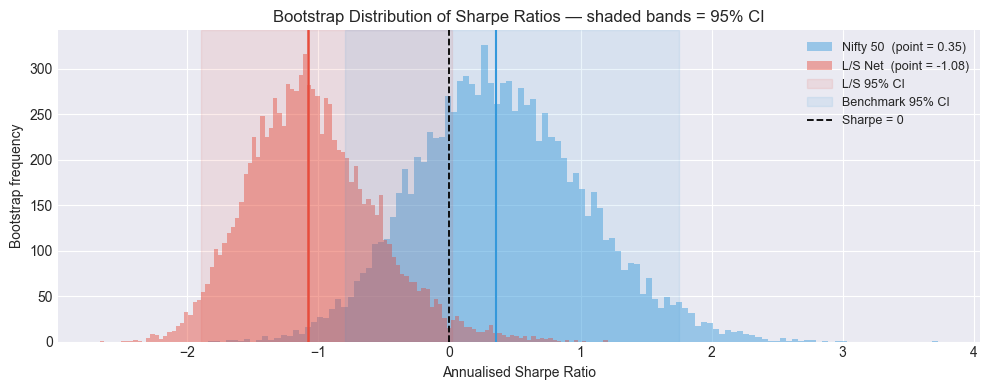

In [18]:
# ── Sharpe Ratio — Bootstrap Confidence Intervals (10,000 resamples) ─────────
np.random.seed(42)
N_BOOT = 10_000

def bootstrap_sharpe(returns, n_boot=N_BOOT, ann_factor=252):
    r   = returns.values
    n   = len(r)
    idx = np.random.randint(0, n, size=(n_boot, n))
    s   = r[idx]
    ann_ret = (1 + s.mean(axis=1)) ** ann_factor - 1
    ann_vol = s.std(axis=1) * np.sqrt(ann_factor)
    with np.errstate(invalid="ignore", divide="ignore"):
        sharpes = np.where(ann_vol > 0, (ann_ret - RISK_FREE_ANNUAL) / ann_vol, np.nan)
    return sharpes

boot_gross = bootstrap_sharpe(results_df["Portfolio_Gross"])
boot_net   = bootstrap_sharpe(results_df["Portfolio"])
boot_bench = bootstrap_sharpe(results_df["Benchmark"])

def ci95(arr):
    return np.nanpercentile(arr, 2.5), np.nanpercentile(arr, 97.5)

gross_sharpe = gross_stats[2]
port_sharpe  = net_stats[2]
bench_sharpe = bench_stats[2]
ci_gross = ci95(boot_gross)
ci_net   = ci95(boot_net)
ci_bench = ci95(boot_bench)
pval_net   = (boot_net   <= 0).mean()
pval_bench = (boot_bench <= 0).mean()

ci_df = pd.DataFrame({
    "Point Estimate": [f"{gross_sharpe:.3f}",  f"{port_sharpe:.3f}",  f"{bench_sharpe:.3f}"],
    "95% CI Lower"  : [f"{ci_gross[0]:.3f}",   f"{ci_net[0]:.3f}",    f"{ci_bench[0]:.3f}"],
    "95% CI Upper"  : [f"{ci_gross[1]:.3f}",   f"{ci_net[1]:.3f}",    f"{ci_bench[1]:.3f}"],
    "p (Sharpe > 0)": ["—",                    f"{pval_net:.3f}",      f"{pval_bench:.3f}"],
}, index=["L/S Momentum (Gross)", "L/S Momentum (Net)", "Nifty 50 Benchmark"])

print("=" * 60)
print("  SHARPE RATIO — 95% Bootstrap Confidence Intervals")
print(f"  ({N_BOOT:,} resamples, IID daily returns assumed)")
print("=" * 60)
display(ci_df)

sig = "SIGNIFICANT ✓" if pval_net < 0.05 else "NOT significant ✗"
print(f"\nNet L/S Sharpe is {sig} at the 5% level")
print(f"(p = {pval_net:.3f}  —  fraction of bootstrap samples with Sharpe ≤ 0)")

# ── Bootstrap distribution plot ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(boot_bench, bins=120, alpha=0.45, color="#3498db", label=f"Nifty 50  (point = {bench_sharpe:.2f})")
ax.hist(boot_net,   bins=120, alpha=0.45, color="#e74c3c", label=f"L/S Net  (point = {port_sharpe:.2f})")
ax.axvspan(ci_net[0],   ci_net[1],   alpha=0.10, color="#e74c3c", label="L/S 95% CI")
ax.axvspan(ci_bench[0], ci_bench[1], alpha=0.10, color="#3498db", label="Benchmark 95% CI")
ax.axvline(0, color="black", linewidth=1.3, linestyle="--", label="Sharpe = 0")
ax.axvline(port_sharpe,  color="#e74c3c", linewidth=1.8)
ax.axvline(bench_sharpe, color="#3498db", linewidth=1.5)
ax.set_xlabel("Annualised Sharpe Ratio")
ax.set_ylabel("Bootstrap frequency")
ax.set_title("Bootstrap Distribution of Sharpe Ratios — shaded bands = 95% CI")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()


In [ ]:
# ── Visualisations ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    f"Nifty 50 Futures — HCD-Filtered Momentum Strategy  |  ₹{INITIAL_CAPITAL/1e5:.0f}L capital\n"
    f"Refresh only on predicted High-Conviction Days  |  "
    f"{results_df.index[0].date()} → {results_df.index[-1].date()}",
    fontsize=12, fontweight="bold"
)

# ── 1. Portfolio value in ₹ (with HCD refresh days shaded) ───────────────────
ax = axes[0, 0]
hcd_dates = results_df[results_df["Is_HCD"]].index
ax.plot(results_df.index, results_df["Benchmark_INR"],
        label="Nifty 50 Benchmark", color="#3498db", linewidth=1.5)
ax.plot(results_df.index, INITIAL_CAPITAL * cum_port_gross,
        label="L/S Momentum (Gross)", color="#f39c12", linewidth=1.4, linestyle=":")
ax.plot(results_df.index, results_df["Portfolio_INR"],
        label="L/S Momentum (Net)", color="#e74c3c", linewidth=1.8, linestyle="--")
# Mark HCD refresh days as vertical ticks at the bottom
y_min = results_df["Portfolio_INR"].min() * 0.985
for d in hcd_dates[::3]:   # every 3rd to avoid overplotting
    ax.axvline(d, color="#2ecc71", alpha=0.12, linewidth=1.0)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"₹{x/1e5:.1f}L"))
ax.set_title(f"Portfolio Value (₹)  — green shading = HCD refresh days ({hcd_pct:.0%})")
ax.legend(fontsize=9)

# ── 2. Score spread + HCD threshold over time ─────────────────────────────────
ax = axes[0, 1]
bt_start = results_df.index[0]
conv_bt  = conv_df.loc[conv_df.index >= bt_start]
sma_bt   = conv_bt["spread"].rolling(10).mean()
rq_bt    = conv_df["spread"].rolling(90, min_periods=30).quantile(CONVICTION_PCTILE).reindex(conv_bt.index)
ax.plot(conv_bt.index, sma_bt, color="#3498db", lw=1.0, label="Score spread (10d MA)")
ax.plot(conv_bt.index, rq_bt,  color="#e74c3c", lw=1.0, ls="--",
        label=f"Rolling {CONVICTION_PCTILE:.0%}-tile HCD threshold")
ax.fill_between(conv_bt.index, 0, float(sma_bt.max()),
                where=(conv_bt["pred_hcd"] == 1), alpha=0.22,
                color="#2ecc71", label="Predicted HCD (refresh)")
ax.set_title("Score Spread + HCD Predictions")
ax.set_ylabel("Score spread")
ax.legend(fontsize=9)

# ── 3. Rolling 252-day Sharpe ─────────────────────────────────────────────────
ax = axes[1, 0]
roll_sharpe_port  = (
    (results_df["Portfolio"].rolling(252).mean() * ann - RISK_FREE_ANNUAL) /
    (results_df["Portfolio"].rolling(252).std() * np.sqrt(ann))
)
roll_sharpe_bench = (
    (results_df["Benchmark"].rolling(252).mean() * ann - RISK_FREE_ANNUAL) /
    (results_df["Benchmark"].rolling(252).std() * np.sqrt(ann))
)
ax.plot(roll_sharpe_bench.index, roll_sharpe_bench.values,
        label="Nifty 50", color="#3498db", linewidth=1.5)
ax.plot(roll_sharpe_port.index, roll_sharpe_port.values,
        label="L/S Momentum (Net)", color="#e74c3c", linewidth=1.8, linestyle="--")
ax.axhline(0, color="black", linewidth=0.8, linestyle=":")
ax.set_title("Rolling 252-day Sharpe Ratio")
ax.set_ylabel("Sharpe")
ax.legend(fontsize=9)

# ── 4. Monthly return heatmap ─────────────────────────────────────────────────
ax = axes[1, 1]
monthly_port = results_df["Portfolio"].resample("ME").apply(lambda r: (1 + r).prod() - 1)
df_heat = monthly_port.to_frame("ret")
df_heat["Year"]  = df_heat.index.year
df_heat["Month"] = df_heat.index.month
grid = df_heat.pivot(index="Year", columns="Month", values="ret")
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
grid.columns = [month_names[m - 1] for m in grid.columns]
sns.heatmap(grid * 100, ax=ax, annot=True, fmt=".1f", center=0,
            cmap="RdYlGn", linewidths=0.4, cbar_kws={"label": "%"},
            annot_kws={"size": 8})
ax.set_title("Monthly Returns (L/S Portfolio, %)")
ax.set_ylabel("Year")
ax.set_xlabel("")

plt.tight_layout()
plt.show()


In [ ]:
# ── Signal attribution — which indicator drove the long vs short picks? ────────
# Sample every 5 trading days (representative; avoids looping 750+ days)
contribution_records = []

for i in range(ROLLING_DAYS, len(days) - 1, 5):
    all_z = {}
    for name in SIGNAL_WEIGHTS:
        row   = signal_dfs[name].iloc[i]
        valid = row.dropna()
        if len(valid) < 10:
            continue
        mu, sigma = valid.mean(), valid.std()
        if sigma < 1e-9:
            continue
        all_z[name] = (valid - mu) / sigma

    if len(all_z) < 3:
        continue

    z_df = pd.DataFrame(all_z).dropna()
    if len(z_df) < 4:
        continue

    composite = sum(z_df[n] * w for n, w in SIGNAL_WEIGHTS.items() if n in z_df)
    sorted_c  = composite.sort_values(ascending=False)
    long_t    = [sorted_c.index[0]]           # #1 momentum
    short_t   = [sorted_c.index[-1]]          # #50 momentum

    for sig_name in SIGNAL_WEIGHTS:
        if sig_name not in z_df.columns:
            continue
        long_contrib  = float(z_df.loc[long_t,  sig_name].mean()) * SIGNAL_WEIGHTS[sig_name]
        short_contrib = float(z_df.loc[short_t, sig_name].mean()) * SIGNAL_WEIGHTS[sig_name]
        contribution_records.append({
            "Signal": sig_name,
            "Long side avg z-score contribution":  long_contrib,
            "Short side avg z-score contribution": short_contrib,
        })

if contribution_records:
    contrib_df = pd.DataFrame(contribution_records).groupby("Signal").mean()
    contrib_df["Long − Short spread"] = (
        contrib_df["Long side avg z-score contribution"] -
        contrib_df["Short side avg z-score contribution"]
    )
    contrib_df = contrib_df.sort_values("Long − Short spread", ascending=False)

    fig, ax = plt.subplots(figsize=(10, 4))
    x = range(len(contrib_df))
    ax.bar([v - 0.2 for v in x], contrib_df["Long side avg z-score contribution"],
           width=0.35, color="#2ecc71", label="Long (#1 stock) avg contribution")
    ax.bar([v + 0.2 for v in x], contrib_df["Short side avg z-score contribution"],
           width=0.35, color="#e74c3c", label="Short (#50 stock) avg contribution")
    ax.set_xticks(list(x))
    ax.set_xticklabels(contrib_df.index, rotation=15)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("Average Per-Signal Contribution to #1 Long vs #50 Short (sampled every 5 days)")
    ax.set_ylabel("Weighted z-score contribution")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()

    print("\nSignal attribution (average weighted z-score contribution):")
    display(contrib_df.round(4))


In [ ]:
# ── Today's LONG / SHORT signals + Tomorrow's HCD Prediction ─────────────────
latest_i      = len(stock_prices) - 1
latest_scores = composite_score_at(latest_i)
latest_date   = stock_prices.index[latest_i].date()
current_pv    = results_df["Portfolio_INR"].iloc[-1]

print(f"{'=' * 64}")
print(f"  TODAY'S SIGNALS  —  {latest_date}")
print(f"  (enter at TOMORROW's market open)")
print(f"  Current portfolio value : ₹{current_pv:,.2f}")
print(f"{'=' * 64}")

if latest_scores is None:
    print("  Not enough history. Run data download first.")
else:
    sorted_scores = latest_scores.sort_values(ascending=False)
    n             = len(sorted_scores)
    vix_now       = float(vix_daily.iloc[-1]) if len(vix_daily) > 0 else np.nan
    scale_now     = vix_scale(stock_prices.index[-1])

    # ── HCD prediction for TOMORROW ───────────────────────────────────────────
    today_ts = stock_prices.index[-1]
    if today_ts in conv_df.index:
        today_spread = conv_df.loc[today_ts, "spread"]
        today_prob   = conv_df.loc[today_ts, "pred_prob"]
        today_pred   = conv_df.loc[today_ts, "pred_hcd"]
        thr_val      = float(rolling_q.dropna().iloc[-1])
    else:
        today_spread = np.nan
        today_prob   = np.nan
        today_pred   = np.nan
        thr_val      = np.nan

    # ── VIX status ────────────────────────────────────────────────────────────
    print(f"\n  India VIX (latest) : {vix_now:.1f}  →  Exposure scale: {scale_now:.0%}")
    if scale_now == 0.0:
        print("  ⚠  HIGH VIX — STAY FLAT, no new positions today")
    elif scale_now < 1.0:
        print("  ⚠  ELEVATED VIX — trade at HALF position size")
    else:
        print("  ✓  Normal VIX — full position size")

    # ── HCD prediction block ──────────────────────────────────────────────────
    print(f"\n  ── TOMORROW'S HCD PREDICTION ────────────────────────────────")
    if not np.isnan(today_spread):
        is_tomorrow_hcd = (not pd.isna(today_pred)) and (today_pred == 1.0)
        hcd_label = "✅  HIGH-CONVICTION DAY" if is_tomorrow_hcd else "⏸  Normal day (hold positions)"
        print(f"  Today's score spread  : {today_spread:.3f}  (threshold = {thr_val:.3f})")
        print(f"  HCD probability       : {today_prob:.1%}")
        print(f"  Tomorrow's prediction : {hcd_label}")
        if is_tomorrow_hcd:
            print(f"\n  ► ACTION: Refresh positions at tomorrow's open using signals below.")
        else:
            print(f"\n  ► ACTION: HOLD current positions, do NOT refresh tomorrow.")
    else:
        print("  Prediction not available (predictor not yet trained for this date)")
    print(f"  {'─' * 60}")

    long_ticker  = sorted_scores.index[0]
    short_ticker = sorted_scores.index[-1]
    long_alloc   = current_pv * LONG_WEIGHT  * scale_now
    short_alloc  = current_pv * SHORT_WEIGHT * scale_now
    cash_held    = current_pv * (1 - scale_now)

    print(f"\n  {'Action':<8} {'Ticker':<16} {'Score':>8}   {'₹ Allocated':>14}  {'Leg'}")
    print(f"  {'-' * 62}")
    print(f"  {'BUY  ▲':<8} {long_ticker:<16} {sorted_scores.iloc[0]:>8.4f}   ₹{long_alloc:>12,.0f}  Long leg")
    print(f"  {'SELL ▼':<8} {short_ticker:<16} {sorted_scores.iloc[-1]:>8.4f}   ₹{short_alloc:>12,.0f}  Short leg")
    if cash_held > 0:
        print(f"  {'CASH':<8} {'(T-Bills/liquid)':<16} {'':>8}   ₹{cash_held:>12,.0f}  Uninvested")

    # ── Full ranking (compact view) ───────────────────────────────────────────
    print(f"\n  Full ranking (top 5 and bottom 5):")
    print(f"  {'Rank':<5} {'Ticker':<16} {'Score':>8}   Signal")
    print(f"  {'-' * 48}")
    for rank, (ticker, score) in enumerate(sorted_scores.items(), 1):
        if rank <= 5:
            sig = "LONG  ▲" if rank == 1 else "neutral"
        elif rank > n - 5:
            sig = "SHORT ▼" if rank == n else "neutral"
        else:
            continue
        flag = "  ← ACTIVE" if rank == 1 or rank == n else ""
        print(f"  {rank:<5} {ticker:<16} {score:>8.4f}   {sig}{flag}")

    # ── Signal breakdown for the 2 active positions ───────────────────────────
    print(f"\n  Signal breakdown for active positions:")
    rows = []
    for t, side in [(long_ticker, "LONG  ▲"), (short_ticker, "SHORT ▼")]:
        p = price_panel[t]
        rows.append({
            "Ticker"    : t.replace(".NS", ""),
            "Side"      : side,
            "Score"     : round(sorted_scores[t], 4),
            "₹ Alloc"   : f"₹{(long_alloc if side.startswith('L') else short_alloc):,.0f}",
            "ROC_6mo"   : f"{compute_roc(p, ROC_LONG).iloc[-1]:.2%}",
            "ROC_3mo"   : f"{compute_roc(p, ROC_MED).iloc[-1]:.2%}",
            "ROC_1mo"   : f"{compute_roc(p, ROC_SHORT).iloc[-1]:.2%}",
            "RSI_14"    : f"{compute_rsi(p, RSI_WINDOW).iloc[-1]:.1f}",
            "MACD_Hist" : f"{compute_macd_hist(p, MACD_FAST, MACD_SLOW, MACD_SIG).iloc[-1]:.4f}",
            "MA_Cross%" : f"{compute_ma_cross(p, EMA_FAST, EMA_SLOW).iloc[-1]:.3%}",
            "High52w%"  : f"{compute_high52w_ratio(p, HIGH52W_WINDOW).iloc[-1]:.2%}",
        })
    detail_df = pd.DataFrame(rows).set_index("Ticker")
    display(detail_df)
